In [1]:
%pip install numpy matplotlib scikit-learn pandas scipy seaborn --quiet


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde, skew, kurtosis
import seaborn as sns
import os

In [3]:
T = 5.0          # Time horizon in days
N_steps = 2000   # Time discretization steps
dt = T / N_steps
sq_dt = np.sqrt(dt)
t = np.linspace(0.0, T, N_steps + 1)

N_paths = 3000   # Monte Carlo sample paths

# Model parameters (typical normalized benchmark values)
alpha1, beta1, gamma1 = 1.0, 1.2, 0.15
alpha2, beta2, gamma2 = 1.0, 1.0, 0.20
a = 0.05
b = 1.50

# Initial conditions [X1_0, X2_0, X3_0, X4_0, X5_0]
# X1: Eq tank volume, X2: flow rate, X3: raw dirtiness,
# X4: equalized dirtiness, X5: reactor effluent dirtiness
X1_0 = 10.0
X2_0 = (alpha1 + 1.0) / beta1  # Steady-state balance condition
X3_0 = 5.0
X4_0 = 4.0
X5_0 = 1.0

In [4]:
X = np.zeros((5, N_steps + 1, N_paths))
X[0, 0, :] = X1_0
X[1, 0, :] = X2_0
X[2, 0, :] = X3_0
X[3, 0, :] = X4_0
X[4, 0, :] = X5_0

for n in range(N_steps):
    # Current state vectors across all paths
    x1 = np.maximum(X[0, n, :], 1e-4)  # Prevent zero-division in volume
    x2 = np.maximum(X[1, n, :], 0.0)
    x3 = np.maximum(X[2, n, :], 0.0)
    x4 = np.maximum(X[3, n, :], 0.0)
    x5 = np.maximum(X[4, n, :], 0.0)

    # Gaussian random variables for W1 and W2
    Z1 = np.random.normal(0.0, 1.0, size=N_paths)
    Z2 = np.random.normal(0.0, 1.0, size=N_paths)

    # Diffusions for states 2 and 3
    diff2 = np.sqrt(2.0 * gamma1 * x2 / x1) * sq_dt * Z1
    diff3 = np.sqrt(2.0 * gamma2 * x3 / x1) * sq_dt * Z2

    # Update Equations (6.1) - (6.5)
    # X1 (ODE): Tank volume
    X[0, n + 1, :] = x1 + (((alpha1 + 1.0) / beta1) - x2) * dt

    # X2 (SDE): Influent flow rate
    X[1, n + 1, :] = x2 + (alpha1 + 1.0 - beta1 * (x2 / x1)) * dt + diff2

    # X3 (SDE): Influent waste concentration
    X[2, n + 1, :] = x3 + ((alpha2 + 1.0 - beta2 * x3) / x1) * dt + diff3

    # X4 (ODE): Equalization tank effluent
    X[3, n + 1, :] = x4 + ((x3 - x4) * (x2 / x1)) * dt

    # X5 (ODE): Reactor treated effluent
    X[4, n + 1, :] = x5 + (a + b * (x4 - x5)) * dt


In [5]:
ratio = X[4, :, :] / np.maximum(X[2, :, :], 1e-4)

# Expected ratio over time
mean_ratio = np.mean(ratio, axis=1)
pct_10 = np.percentile(ratio, 10, axis=1)
pct_90 = np.percentile(ratio, 90, axis=1)

fig, axs = plt.subplots(2, 2, figsize=(14, 9))

# Plot 1: Input Noise (X2 Flow and X3 Load)
axs[0, 0].plot(t, X[1, :, :3], alpha=0.6, lw=1.2)
axs[0, 0].plot(t, X[2, :, :3], alpha=0.6, lw=1.2, linestyle="--")
axs[0, 0].set_title("Input Dynamics: Flow ($X^2$, solid) & Influent COD ($X^3$, dashed)")
axs[0, 0].set_xlabel("Time (days)")
axs[0, 0].grid(True, linestyle="--", alpha=0.5)

# Plot 2: Equalization Smoothing (X3 vs X4)
sample_idx = 0
axs[0, 1].plot(t, X[2, :, sample_idx], label="Raw Input ($X^3$)", color="crimson", alpha=0.7)
axs[0, 1].plot(t, X[3, :, sample_idx], label="Equalized ($X^4$)", color="navy", lw=2)
axs[0, 1].set_title("Equalization Effect: Raw $X^3$ vs Buffered $X^4$ (Single Path)")
axs[0, 1].set_xlabel("Time (days)")
axs[0, 1].legend()
axs[0, 1].grid(True, linestyle="--", alpha=0.5)

# Plot 3: Final Effluent Quality (X5)
mean_x5 = np.mean(X[4, :, :], axis=1)
axs[1, 0].plot(t, X[4, :, :10], color="gray", alpha=0.3, lw=0.8)
axs[1, 0].plot(t, mean_x5, color="darkgreen", lw=2.2, label=r"Ensemble Mean $\mathbb{E}[X^5]$")
axs[1, 0].set_title("Final Effluent Concentration ($X^5$)")
axs[1, 0].set_xlabel("Time (days)")
axs[1, 0].legend()
axs[1, 0].grid(True, linestyle="--", alpha=0.5)

# Plot 4: Harris Performance Index E[X5 / X3]
axs[1, 1].plot(t, mean_ratio, color="purple", lw=2.2, label=r"$\mathbb{E}[X^5_t / X^3_t]$")
axs[1, 1].fill_between(t, pct_10, pct_90, color="purple", alpha=0.2, label="10th–90th Percentile")
axs[1, 1].set_title(r"Expected Reduction Ratio $\mathbb{E}[X^5 / X^3]$")
axs[1, 1].set_xlabel("Time (days)")
axs[1, 1].legend()
axs[1, 1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

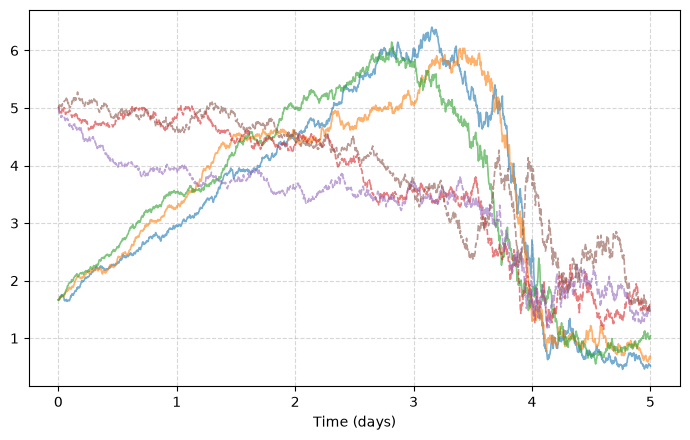

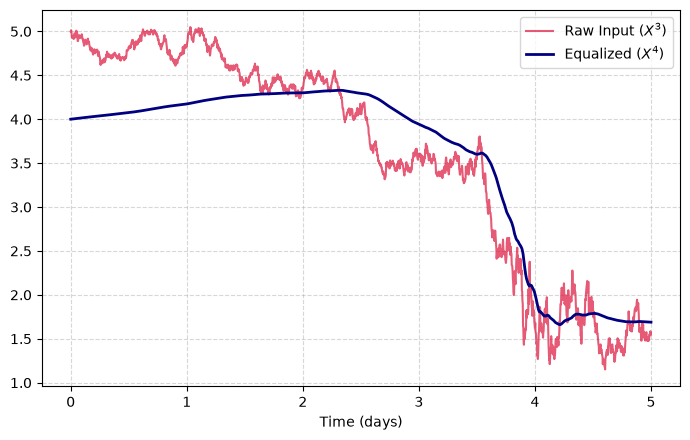

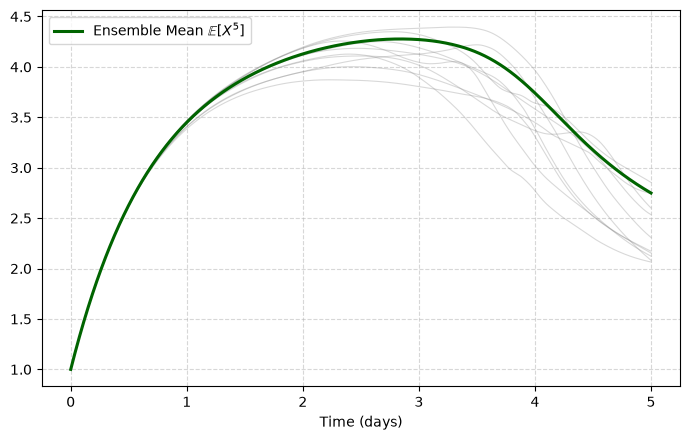

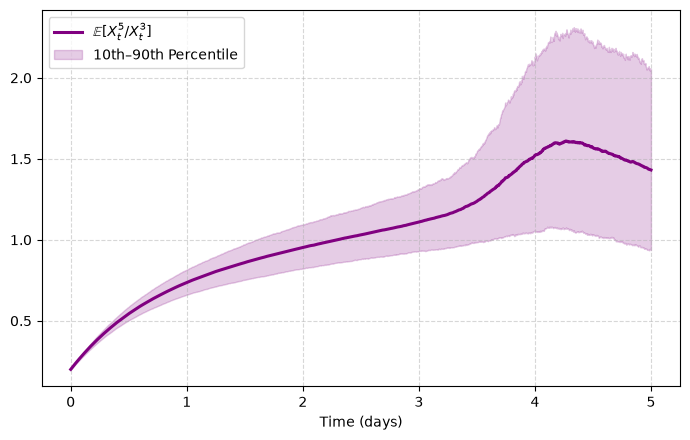

In [6]:
# Ensure directory exists
output_dir = "plotsvg"
os.makedirs(output_dir, exist_ok=True)

# Plot 1: Input Dynamics (Flow & Influent COD)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(t, X[1, :, :3], alpha=0.6, lw=1.2)
ax.plot(t, X[2, :, :3], alpha=0.6, lw=1.2, linestyle="--")
ax.set_xlabel("Time (days)")
ax.grid(True, linestyle="--", alpha=0.5)
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "input_dynamics.pdf"), format="pdf")
plt.show()

# Plot 2: Equalization Effect (Raw vs Buffered)
fig, ax = plt.subplots(figsize=(7, 4.5))
sample_idx = 0
ax.plot(
    t, X[2, :, sample_idx], label="Raw Input ($X^3$)", color="crimson", alpha=0.7
)
ax.plot(
    t, X[3, :, sample_idx], label="Equalized ($X^4$)", color="navy", lw=2
)
ax.set_xlabel("Time (days)")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5)
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "equalization_effect.pdf"), format="pdf")
plt.show()

# Plot 3: Final Effluent Quality ($X^5$)
fig, ax = plt.subplots(figsize=(7, 4.5))
mean_x5 = np.mean(X[4, :, :], axis=1)
ax.plot(t, X[4, :, :10], color="gray", alpha=0.3, lw=0.8)
ax.plot(
    t,
    mean_x5,
    color="darkgreen",
    lw=2.2,
    label=r"Ensemble Mean $\mathbb{E}[X^5]$",
)
ax.set_xlabel("Time (days)")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5)
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "effluent_quality.pdf"), format="pdf")
plt.show()

# Plot 4: Expected Reduction Ratio ($\mathbb{E}[X^5 / X^3]$)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(
    t, mean_ratio, color="purple", lw=2.2, label=r"$\mathbb{E}[X^5_t / X^3_t]$"
)
ax.fill_between(
    t,
    pct_10,
    pct_90,
    color="purple",
    alpha=0.2,
    label="10th–90th Percentile",
)
ax.set_xlabel("Time (days)")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5)
fig.tight_layout()
fig.savefig(os.path.join(output_dir, "reduction_ratio.pdf"), format="pdf")
plt.show()

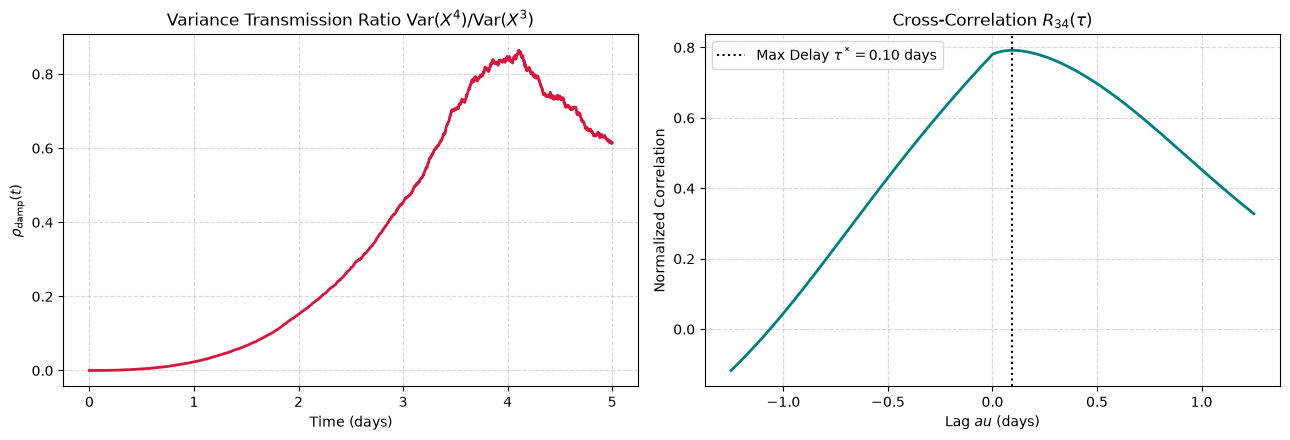

In [8]:
# 1. Variance Damping Ratio over time
var_x3 = np.var(X[2, :, :], axis=1)
var_x4 = np.var(X[3, :, :], axis=1)
damping_ratio = var_x4 / np.maximum(var_x3, 1e-6)

# 2. Empirical Cross-Correlation to find lag tau*
# Subtract mean across time for each path to correlate fluctuations
x3_centered = X[2, :, :] - np.mean(X[2, :, :], axis=0, keepdims=True)
x4_centered = X[3, :, :] - np.mean(X[3, :, :], axis=0, keepdims=True)

# Average cross-correlation across all paths
max_lag = int(N_steps / 4)
lags = np.arange(-max_lag, max_lag + 1)
ccorr = np.zeros(len(lags))

for idx, lag in enumerate(lags):
    if lag < 0:
        ccorr[idx] = np.mean(x3_centered[-lag:, :] * x4_centered[:lag, :])
    elif lag > 0:
        ccorr[idx] = np.mean(x3_centered[:-lag, :] * x4_centered[lag:, :])
    else:
        ccorr[idx] = np.mean(x3_centered * x4_centered)

ccorr /= (np.std(X[2, :, :]) * np.std(X[3, :, :]))
lag_times = lags * dt
tau_star = lag_times[np.argmax(ccorr)]

# Plotting
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(t, damping_ratio, color='crimson', lw=2)
ax[0].set_title(r"Variance Transmission Ratio $\mathrm{Var}(X^4)/\mathrm{Var}(X^3)$")
ax[0].set_xlabel("Time (days)")
ax[0].set_ylabel(r"$\rho_{\mathrm{damp}}(t)$")
ax[0].grid(True, linestyle="--", alpha=0.5)

ax[1].plot(lag_times, ccorr, color='teal', lw=2)
ax[1].axvline(tau_star, color='black', linestyle=':', label=f"Max Delay $\\tau^* = {tau_star:.2f}$ days")
ax[1].set_title(r"Cross-Correlation $R_{34}(\tau)$")
ax[1].set_xlabel("Lag $\tau$ (days)")
ax[1].set_ylabel("Normalized Correlation")
ax[1].legend()
ax[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
# Regulatory limit for treated effluent COD
C_crit = 3.5

# 1. First Hitting Time (FHT) computation
# Find first index where X5 >= C_crit
breach_mask = X[4, :, :] >= C_crit
has_breached = np.any(breach_mask, axis=0)

# Argmax returns first True index along axis 0
first_breach_idx = np.argmax(breach_mask, axis=0)
fht_values = t[first_breach_idx[has_breached]]

# 2. Cumulative Breach Probability over time P(sup_{s <= t} X_s^5 >= C_crit)
running_max_x5 = np.maximum.accumulate(X[4, :, :], axis=0)
p_cumulative_breach = np.mean(running_max_x5 >= C_crit, axis=1)
survival_function = 1.0 - p_cumulative_breach

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# FHT Distribution
if len(fht_values) > 0:
    ax[0].hist(fht_values, bins=30, density=True, color='darkorange', alpha=0.7, edgecolor='black')
ax[0].set_title(f"First Hitting Time Density ($X^5 \\geq {C_crit}$)")
ax[0].set_xlabel(r"First Breach Time $\tau$ (days)")
ax[0].set_ylabel("Empirical Density")
ax[0].grid(True, linestyle="--", alpha=0.5)

# Survival Function (changed \le to \leq)
ax[1].plot(t, survival_function, color='darkblue', lw=2, label=r"Survival $S(t) = P(\tau > t)$")
ax[1].plot(t, p_cumulative_breach, color='firebrick', lw=2, linestyle='--', label=r"Failure $P(\tau \leq t)$")
ax[1].set_title("Reliability & Violation Risk")
ax[1].set_xlabel("Time (days)")
ax[1].set_ylabel("Probability")
ax[1].legend()
ax[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


In [ ]:
# Time slices to inspect
slice_times = [1.0, 2.5, 4.0, 5.0]
slice_indices = [np.abs(t - st).argmin() for st in slice_times]

plt.figure(figsize=(9, 5))
x_grid = np.linspace(np.min(X[4, slice_indices, :]), np.max(X[4, slice_indices, :]), 300)

for idx, st in zip(slice_indices, slice_times):
    sample = X[4, idx, :]
    kde = gaussian_kde(sample)
    sk = skew(sample)
    kt = kurtosis(sample)
    plt.plot(x_grid, kde(x_grid), lw=2, label=f"$t = {st:.1f}$ d (Skew: {sk:.2f}, Kurt: {kt:.2f})")

plt.axvline(C_crit, color='black', linestyle=':', label=f"Threshold $C_{{crit}} = {C_crit}$")
plt.title("Effluent State Distribution Slices $p(X^5, t)$")
plt.xlabel("Effluent COD $X^5$ (mg/L)")
plt.ylabel("Probability Density")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
# 1. State Covariance Heatmap at t = T
X_final = X[:, -1, :]  # shape: (5, N_paths)
cov_matrix = np.cov(X_final)
state_labels = [r"$X^1$ (Vol)", r"$X^2$ (Flow)", r"$X^3$ (Raw)", r"$X^4$ (Eq)", r"$X^5$ (Out)"]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(cov_matrix, annot=True, fmt=".3f", cmap="vlag", xticklabels=state_labels, yticklabels=state_labels, ax=ax[0])
ax[0].set_title(f"State Covariance Matrix $\\Sigma(t={T})$")

# 2. Phase-space trajectory: Equalized COD vs Effluent COD (X4 vs X5)
# Plot 5 sample trajectories + mean phase curve
for i in range(5):
    ax[1].plot(X[3, :, i], X[4, :, i], alpha=0.3, lw=1)
ax[1].plot(np.mean(X[3, :, :], axis=1), np.mean(X[4, :, :], axis=1), color='black', lw=2.5, label="Mean Phase Trajectory")
ax[1].set_title(r"Phase Plane: Equalized ($X^4$) vs Effluent ($X^5$)")
ax[1].set_xlabel(r"Equalization Tank COD $X^4$")
ax[1].set_ylabel(r"Reactor Effluent COD $X^5$")
ax[1].legend()
ax[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
# Cumulative mass entering plant: integral of X3 * X2 dt
# Cumulative mass exiting plant: integral of X5 * X2 dt (assuming reactor outflow matches inflow)
mass_in = np.cumsum(X[2, :, :] * X[1, :, :] * dt, axis=0)
mass_out = np.cumsum(X[4, :, :] * X[1, :, :] * dt, axis=0)

# Cumulative removal efficiency across paths
eta_mass = 1.0 - (mass_out / np.maximum(mass_in, 1e-4))
mean_eta_mass = np.mean(eta_mass, axis=1)

# Ratio of Expectations (well-behaved alternative to expectation of ratios)
ratio_of_expectations = np.mean(X[4, :, :], axis=1) / np.maximum(np.mean(X[2, :, :], axis=1), 1e-4)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(t, mean_eta_mass * 100, color='darkgreen', lw=2.2)
ax[0].set_title("Cumulative Mass Removal Efficiency $\\eta_{\\mathrm{mass}}(t)$")
ax[0].set_xlabel("Time (days)")
ax[0].set_ylabel("Waste Removed (%)")
ax[0].grid(True, linestyle="--", alpha=0.5)

ax[1].plot(t, ratio_of_expectations, color='indigo', lw=2.2, label=r"$\mathbb{E}[X^5_t] / \mathbb{E}[X^3_t]$")
ax[1].set_title("Macro-Concentration Drop Ratio")
ax[1].set_xlabel("Time (days)")
ax[1].set_ylabel("Mean Ratio")
ax[1].legend()
ax[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


In [ ]:
# Sensitivity sweep across influent noise intensity gamma2
gamma2_grid = np.linspace(0.02, 0.40, 10)
p_breach_results = []
var_effluent_results = []

sweep_paths = 1000  # Smaller paths for swift execution in loop

for g2 in gamma2_grid:
    # Mini-simulation loop
    x1 = np.full(sweep_paths, X1_0)
    x2 = np.full(sweep_paths, X2_0)
    x3 = np.full(sweep_paths, X3_0)
    x4 = np.full(sweep_paths, X4_0)
    x5 = np.full(sweep_paths, X5_0)
    
    max_x5 = np.copy(x5)
    
    for n in range(N_steps):
        x1_safe = np.maximum(x1, 1e-4)
        x2_safe = np.maximum(x2, 0.0)
        x3_safe = np.maximum(x3, 0.0)
        
        z1 = np.random.normal(0.0, 1.0, size=sweep_paths)
        z2 = np.random.normal(0.0, 1.0, size=sweep_paths)
        
        diff2 = np.sqrt(2.0 * gamma1 * x2_safe / x1_safe) * sq_dt * z1
        diff3 = np.sqrt(2.0 * g2 * x3_safe / x1_safe) * sq_dt * z2
        
        x1 = x1_safe + (((alpha1 + 1.0) / beta1) - x2_safe) * dt
        x2 = x2_safe + (alpha1 + 1.0 - beta1 * (x2_safe / x1_safe)) * dt + diff2
        x3 = x3_safe + ((alpha2 + 1.0 - beta2 * x3_safe) / x1_safe) * dt + diff3
        x4 = np.maximum(x4, 0.0) + ((x3_safe - np.maximum(x4, 0.0)) * (x2_safe / x1_safe)) * dt
        x5 = np.maximum(x5, 0.0) + (a + b * (x4 - np.maximum(x5, 0.0))) * dt
        
        max_x5 = np.maximum(max_x5, x5)
        
    p_breach_results.append(np.mean(max_x5 >= C_crit))
    var_effluent_results.append(np.var(x5))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(gamma2_grid, p_breach_results, marker='o', color='crimson', lw=2)
ax[0].set_title(r"Regulatory Breach Probability vs Noise Intensity $\gamma_2$")
ax[0].set_xlabel(r"Diffusion Parameter $\gamma_2$")
ax[0].set_ylabel(r"$P(\sup X^5 \geq C_{\mathrm{crit}})$")
ax[0].grid(True, linestyle="--", alpha=0.5)

ax[1].plot(gamma2_grid, var_effluent_results, marker='s', color='darkslategray', lw=2)
ax[1].set_title(r"Terminal Effluent Variance vs $\gamma_2$")
ax[1].set_xlabel(r"Diffusion Parameter $\gamma_2$")
ax[1].set_ylabel(r"$\mathrm{Var}(X_T^5)$")
ax[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()
